# TP1 - Visión por Computadora I

Especialización en Inteligencia Artificial (CEIA), FIUBA.

**Integrantes**

- Hernando Alexis Gonzalez
- Victoria Villalba Teves
- Silvert Kevin Quispe Pacompia

**Consigna**

- Parte 1 (imágenes en `/white_patch`):
  1. Implementar el algoritmo White Patch para librarnos de las diferencias de color de iluminación.
  2. Mostrar los resultados obtenidos y analizar las posibles fallas (si es que las hay) en el caso de White Patch.
- Parte 2:
  1. Para las imágenes `img1_tp.png` y `img2_tp.png` leerlas con OpenCV en escala de grises y visualizarlas.
  2. Elegir el número de bins que se crea conveniente y graficar su histograma, comparar los histogramas entre sí. Explicar lo que se observa. Si tuviera que entrenar un modelo de clasificación/detección de imágenes, ¿considera que puede ser de utilidad tomar como features a los histogramas?

In [1]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Imágenes provistas por la cátedra en Material_TPs/TP1 del repo del curso
# (https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/vision_computadora_I).
# Están copiadas en ./data para que el notebook sea autocontenido.
DATA_DIR = Path("data")
WHITE_PATCH_DIR = DATA_DIR / "white_patch"


## Parte 1: White Patch

El algoritmo asume que el píxel más brillante de cada canal corresponde a algo blanco
iluminado por la fuente de luz de la escena. Si la luz no es blanca, esos máximos no van a ser
(255, 255, 255), así que se escala cada canal para llevarlos a ese valor:

$$(R, G, B) \rightarrow \left(\frac{255}{R_{max}} R,\ \frac{255}{G_{max}} G,\ \frac{255}{B_{max}} B\right)$$

La función recibe un percentil para poder usarla más adelante con una variante robusta.
Con `percentile=100` el valor de referencia es el máximo, que es el algoritmo tal cual se vio en clase.

In [3]:
def white_patch(img: np.ndarray, percentile: float = 100) -> np.ndarray:
    """
    Parameters
    ----------
    img: np.ndarray
        Imagen BGR de 8 bits
    percentile:
        Percentil de cada canal que se toma como el blanco de la escena.
        Con 100 se usa el máximo (White Patch clásico)

    Return
    ------
    Imagen BGR de 8 bits con el balance de blancos corregido
    """
    # Valor de referencia de cada canal (B, G, R)
    white = np.percentile(img.reshape(-1, 3), percentile, axis=0)
    # Evita dividir por cero si algún canal está completamente en negro
    white = np.maximum(white, 1)

    img_new = img.astype(np.float32) * (255 / white)
    np.clip(img_new, 0, 255, out=img_new)

    return img_new.astype(np.uint8)

In [4]:
def show_images(rows: list[list[np.ndarray]], titles: list[str], names: list[str]) -> None:
    """
    Muestra una grilla de imágenes BGR: una fila por imagen y una columna por versión.

    Parameters
    ----------
    rows: lista de filas, cada fila es una lista de imágenes BGR
    titles: título de cada columna
    names: nombre de cada fila
    """
    n_rows, n_cols = len(rows), len(titles)
    # El alto de cada fila sigue la proporción de sus imágenes para no dejar espacios vacíos
    height = sum(3 * row[0].shape[0] / row[0].shape[1] + 0.5 for row in rows)
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, height), squeeze=False)

    for i, row in enumerate(rows):
        for j, img in enumerate(row):
            # OpenCV trabaja en BGR y matplotlib en RGB
            axs[i, j].imshow(img[:, :, ::-1])
            axs[i, j].set_title(f"{names[i]} - {titles[j]}")
            axs[i, j].axis("off")

    plt.tight_layout()
    plt.show()

In [5]:
# imread en modo color descarta el canal alfa de los png que lo tienen
paths = sorted(p for p in WHITE_PATCH_DIR.iterdir() if p.suffix.lower() in {".png", ".jpg", ".jpeg"})
names = [p.name for p in paths]
images = [cv.imread(str(p)) for p in paths]
assert images and all(img is not None for img in images), f"No se pudieron leer las imágenes de {WHITE_PATCH_DIR}"

for name, img in zip(names, images):
    print(f"{name}: {img.shape}")


test_blue.png: (100, 278, 3)
test_green.png: (100, 278, 3)
test_red.png: (99, 276, 3)
wp_blue.jpg: (1600, 1200, 3)
wp_green.png: (571, 363, 3)
wp_green2.jpg: (1600, 1200, 3)
wp_red.png: (813, 481, 3)
wp_red2.jpg: (1600, 1200, 3)


### Resultados con el algoritmo clásico (máximo de cada canal)

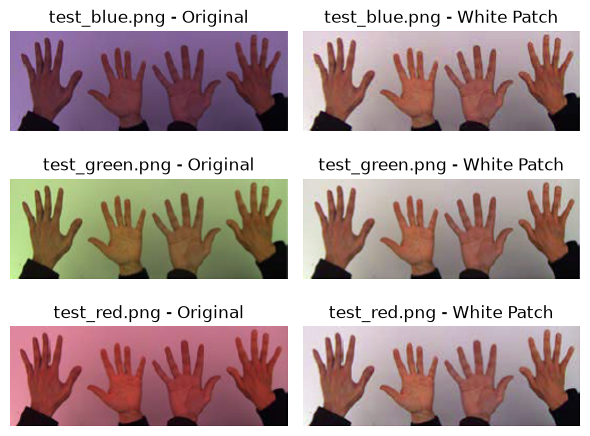

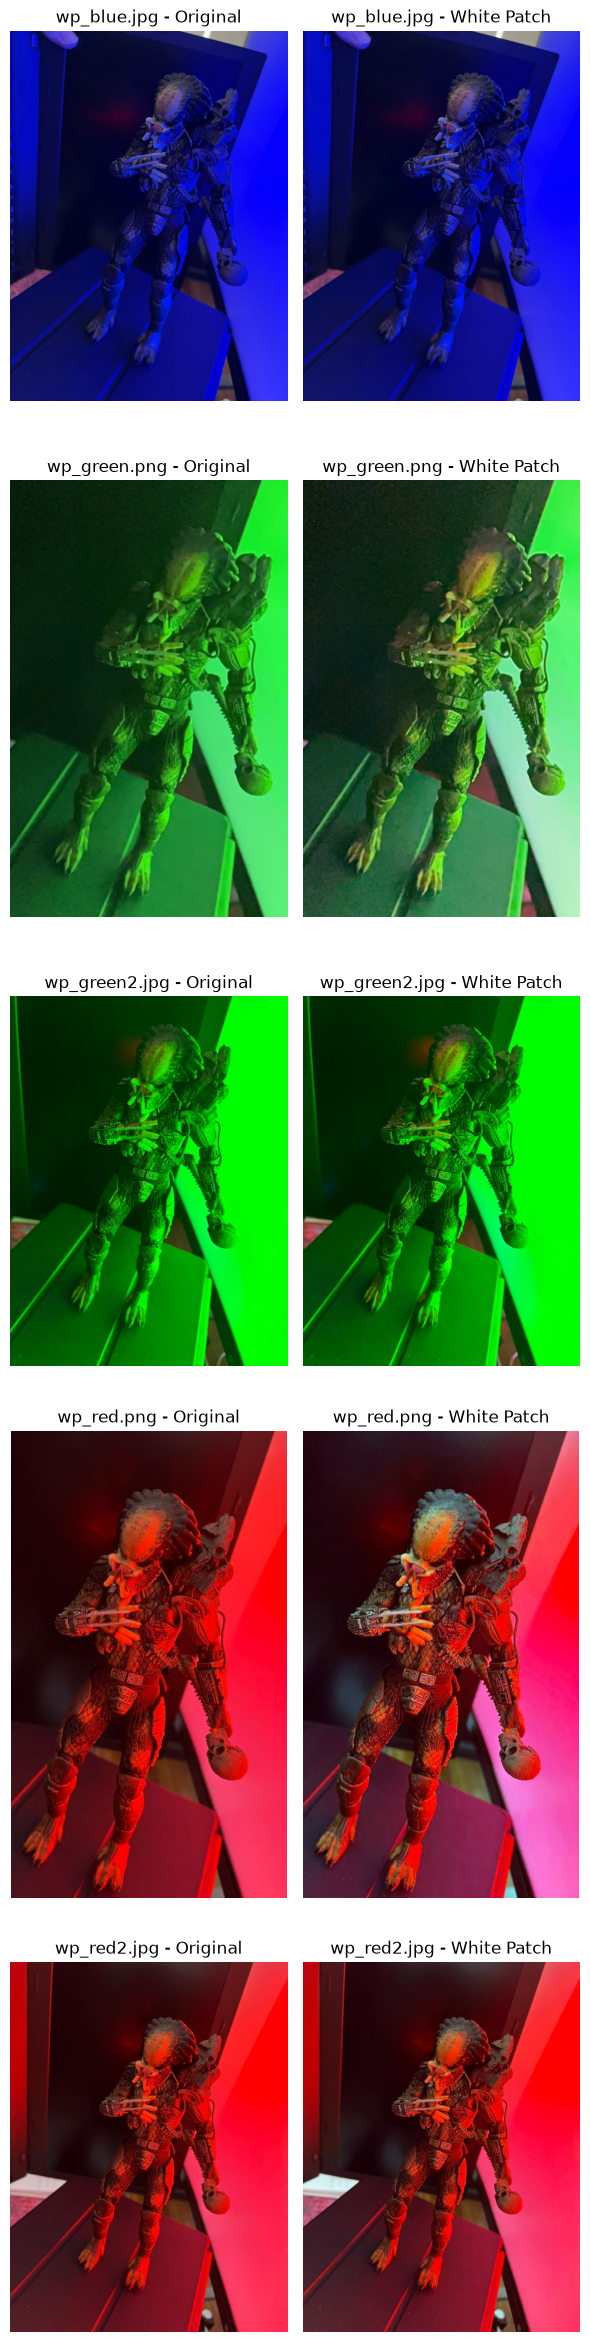

In [6]:
# Se separan las manos (test_*) de la figura (wp_*) porque tienen tamaños muy distintos
groups = {prefix: [i for i, name in enumerate(names) if name.startswith(prefix)]
          for prefix in ["test", "wp"]}

for idx in groups.values():
    rows = [[images[i], white_patch(images[i])] for i in idx]
    show_images(rows, ["Original", "White Patch"], [names[i] for i in idx])

### Análisis de fallas

En las tres imágenes de las manos (`test_*`) el resultado es muy bueno: el fondo pasa a ser
blanco y el color de la piel queda prácticamente igual en las tres, sin importar el color de
la luz original.

En las imágenes de la figura (`wp_*`) solo `wp_green.png` queda aceptable: la pared pasa a
ser casi blanca y la figura recupera algo de color. En el resto el resultado es pobre o
directamente no hay cambio. Para entender por qué, miramos el valor que toma el algoritmo como blanco en cada canal y cuántos
píxeles hay saturados (en 255).

In [7]:
print(f"{'imagen':<16}{'max (B, G, R)':<20}{'% píxeles en 255 (B, G, R)'}")
for name, img in zip(names, images):
    pixels = img.reshape(-1, 3)
    max_values = pixels.max(axis=0)
    saturated = 100 * (pixels == 255).mean(axis=0)
    print(f"{name:<16}{str(max_values):<20}{np.round(saturated, 2)}")

imagen          max (B, G, R)       % píxeles en 255 (B, G, R)
test_blue.png   [200 138 165]       [0. 0. 0.]
test_green.png  [171 250 210]       [0. 0. 0.]
test_red.png    [175 157 247]       [0. 0. 0.]
wp_blue.jpg     [255 255 255]       [0.51 0.   0.  ]
wp_green.png    [155 252 126]       [0. 0. 0.]
wp_green2.jpg   [172 255 170]       [0.   5.14 0.  ]
wp_red.png      [122 134 255]       [0.   0.   6.46]
wp_red2.jpg     [203 201 255]       [0.  0.  9.1]


A partir de esto se ven tres problemas:

1. **El máximo depende de muy pocos píxeles.** En `wp_blue.jpg` hay unos pocos píxeles
   casi blancos en el borde superior, donde se ve directamente la fuente de luz.
   Con eso el máximo da (255, 255, 255), los factores de escala son prácticamente 1 y la imagen
   no cambia. Lo mismo pasa en menor medida en `wp_red2.jpg`, donde un puñado de píxeles
   claros (el papel de la izquierda) lleva el máximo de B y G a ~200 cuando el 99% de los
   píxeles está por debajo de 120.

2. **El canal dominante está saturado.** En `wp_green2.jpg`, `wp_red.png` y `wp_red2.jpg`
   la pared iluminada llega a 255 en el canal del color de la luz (entre el 5% y el 9% de los
   píxeles). Una vez que el sensor satura no sabemos cuánto más brillante era ese canal
   respecto de los otros, así que la proporción que usa el algoritmo para corregir ya está
   subestimada.

3. **La luz es casi monocromática.** En estas escenas los canales que no son el de la luz
   tienen muy poca información (en `wp_green2.jpg` el promedio de B y R es ~4). Escalarlos
   no recupera el color: solo estira unos pocos niveles de intensidad a todo el rango, por eso
   aparecen zonas con colores planos y se amplifica el ruido y los artefactos de compresión
   del jpg. Es el problema de bajo rango dinámico que vimos en clase.

Además, el algoritmo supone que en la escena hay algo blanco. Si no lo hay, el píxel más claro
es de otro color y la corrección lo lleva a blanco igual, cambiando el color de toda la imagen.

### Corrección: usar un percentil en vez del máximo

El primer problema se puede atacar tomando como blanco un percentil alto en lugar del
máximo, de forma que unos pocos píxeles aislados no definan la corrección. El histograma de
cada canal de `wp_blue.jpg` muestra esto: en G y R casi todos los píxeles están por debajo de
~100 y solo una cola de muy pocos píxeles llega hasta 255.

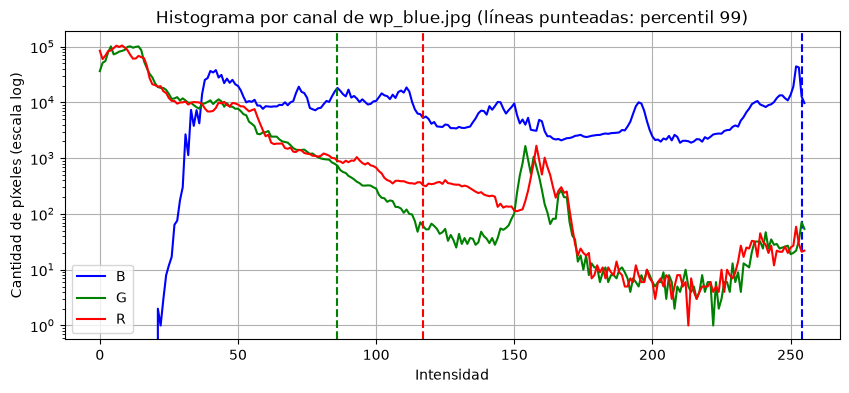

In [8]:
img = images[names.index("wp_blue.jpg")]

plt.figure(figsize=(10, 4))
for channel, color in enumerate(["b", "g", "r"]):
    hist, _ = np.histogram(img[:, :, channel].ravel(), 256, [0, 256])
    plt.plot(hist, color=color, label=color.upper())
    p99 = np.percentile(img[:, :, channel], 99)
    plt.axvline(p99, color=color, linestyle="--")
plt.yscale("log")
plt.xlabel("Intensidad")
plt.ylabel("Cantidad de píxeles (escala log)")
plt.title("Histograma por canal de wp_blue.jpg (líneas punteadas: percentil 99)")
plt.legend()
plt.grid()
plt.show()

Probamos con el percentil 99: es suficiente para descartar los píxeles aislados y no tan bajo
como para que zonas grandes de la imagen terminen saturadas.

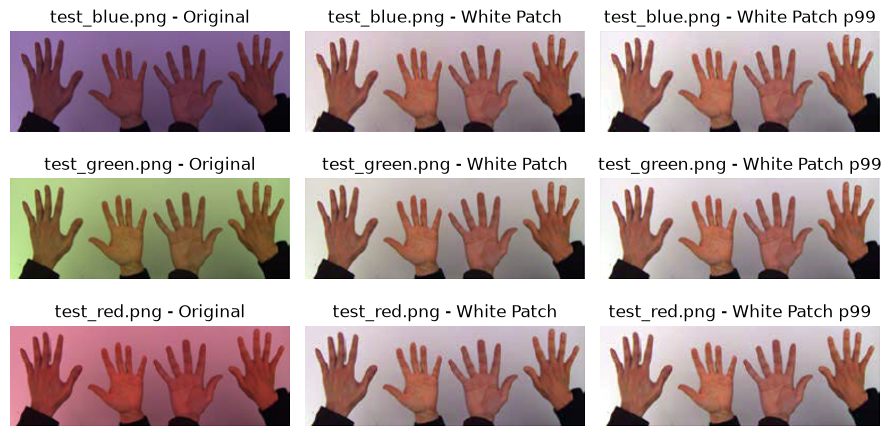

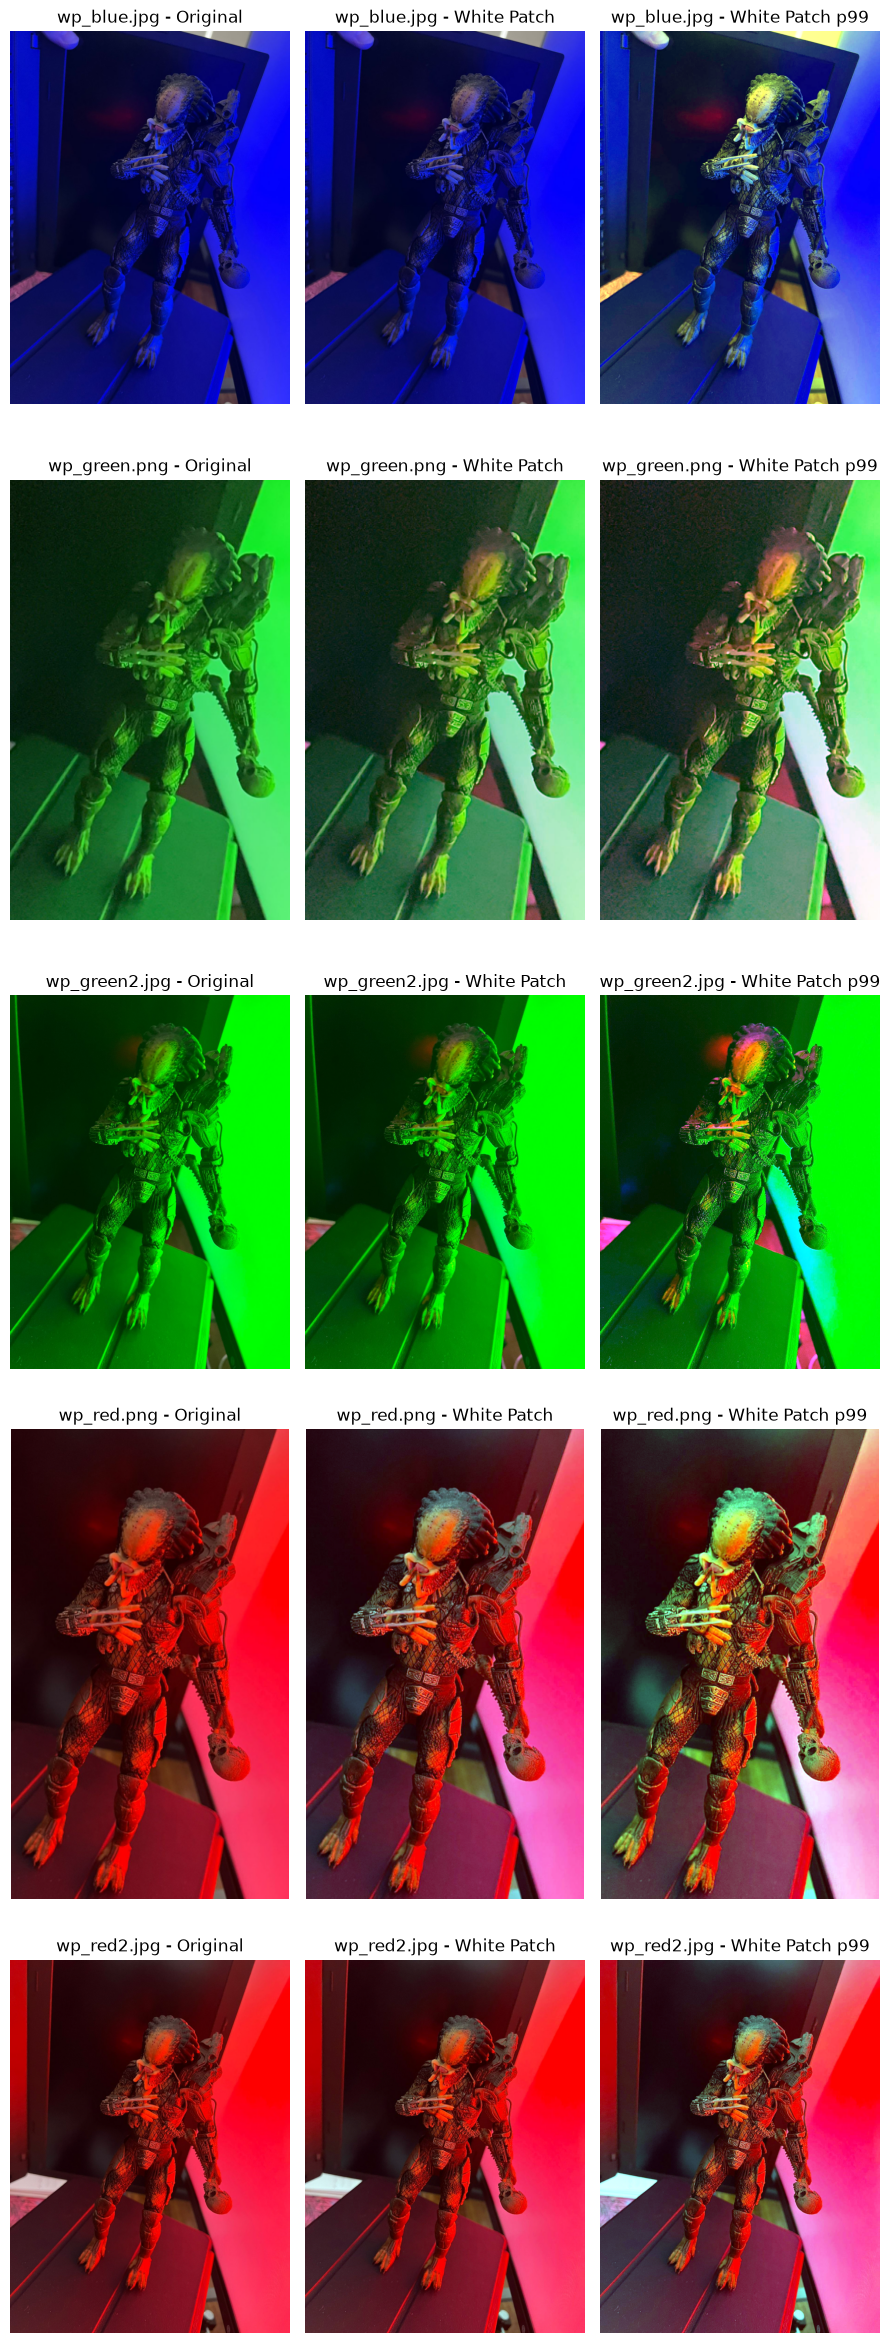

In [9]:
PERCENTILE = 99

titles = ["Original", "White Patch", f"White Patch p{PERCENTILE}"]

for idx in groups.values():
    rows = [[images[i], white_patch(images[i]), white_patch(images[i], PERCENTILE)] for i in idx]
    show_images(rows, titles, [names[i] for i in idx])

Con el percentil 99:

- En las manos y en `wp_green.png` el resultado es prácticamente igual al anterior, como era de
  esperar, porque no había píxeles saturados ni aislados que definieran el máximo.
- `wp_blue.jpg` y `wp_red.png` mejoran bastante: la cabeza y las garras de la figura recuperan
  tonos amarillos y la escena deja de verse de un solo color. En `wp_blue.jpg` la pared sigue
  azulada porque ahí el canal B está saturado (problema 2).
- En `wp_green2.jpg` y `wp_red2.jpg` hay una mejora parcial, pero siguen dominadas por el color
  de la luz y aparecen zonas con colores planos. Acá el problema es el 2 y el 3: la información
  que se perdió por saturación o por tener muy pocos niveles no se puede recuperar con ningún
  escalado por canal.

En conclusión, White Patch funciona bien cuando la luz tiene un tinte moderado, hay algo blanco
en la escena y ningún canal está saturado. Cambiar el máximo por un percentil lo hace más
robusto frente a píxeles aislados, pero no resuelve la saturación ni la iluminación casi
monocromática. Para esos casos la solución tiene que venir del lado de la captura (controlar
la exposición o el balance de blancos de la cámara).

## Parte 2: Histogramas

### Lectura y visualización en escala de grises

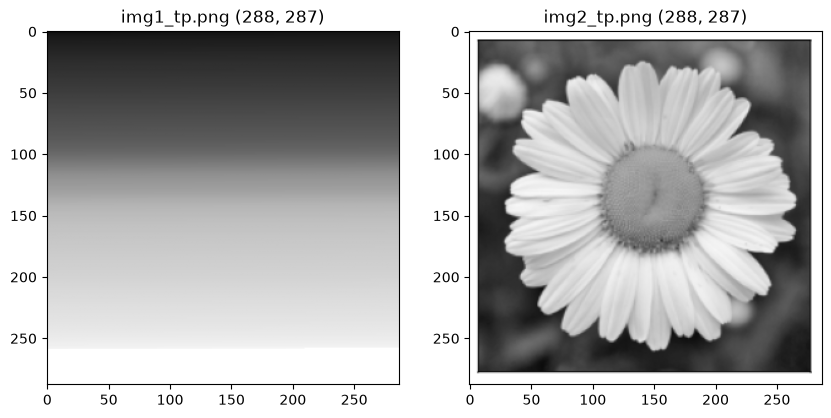

In [10]:
img1 = cv.imread(str(DATA_DIR / "img1_tp.png"), cv.IMREAD_GRAYSCALE)
img2 = cv.imread(str(DATA_DIR / "img2_tp.png"), cv.IMREAD_GRAYSCALE)
assert img1 is not None and img2 is not None, f"No se pudieron leer las imágenes de {DATA_DIR}"

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(img1, cmap="gray", vmin=0, vmax=255)
axs[0].set_title(f"img1_tp.png {img1.shape}")
axs[1].imshow(img2, cmap="gray", vmin=0, vmax=255)
axs[1].set_title(f"img2_tp.png {img2.shape}")
plt.show()

### Histogramas

Usamos 256 bins (uno por nivel de intensidad) para ver la distribución con todo el detalle y
32 bins (8 niveles por bin) para ver la forma general sin tanto ruido.

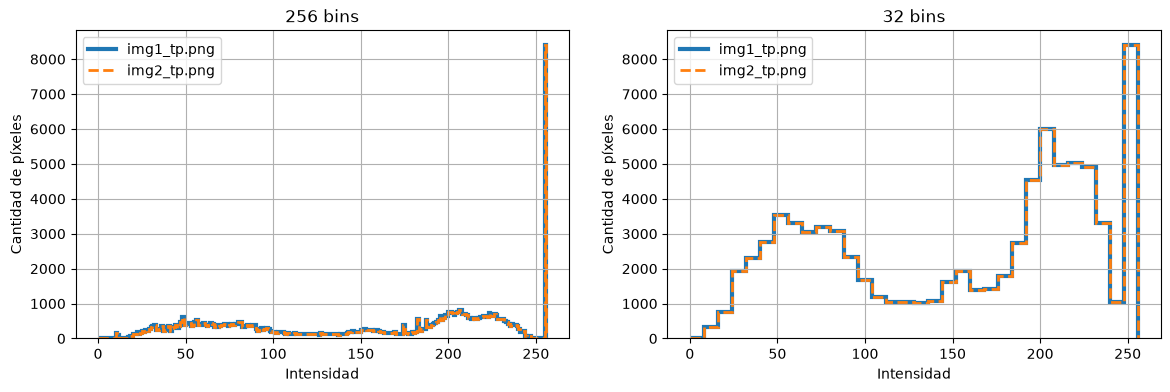

Histogramas iguales: True


In [11]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for ax, bins in zip(axs, [256, 32]):
    hist1, edges = np.histogram(img1.ravel(), bins, [0, 256])
    hist2, _ = np.histogram(img2.ravel(), bins, [0, 256])
    ax.stairs(hist1, edges, label="img1_tp.png", linewidth=3)
    ax.stairs(hist2, edges, label="img2_tp.png", linestyle="--", linewidth=2)
    ax.set_title(f"{bins} bins")
    ax.set_xlabel("Intensidad")
    ax.set_ylabel("Cantidad de píxeles")
    ax.legend()
    ax.grid()
plt.show()

hist1, _ = np.histogram(img1.ravel(), 256, [0, 256])
hist2, _ = np.histogram(img2.ravel(), 256, [0, 256])
print(f"Histogramas iguales: {np.array_equal(hist1, hist2)}")

Los dos histogramas son exactamente iguales, aunque las imágenes no tienen nada que ver: una es
un degradé y la otra es una flor. Esto pasa porque el histograma solo cuenta cuántos píxeles
hay de cada intensidad y no guarda dónde están. De hecho, `img1_tp.png` es `img2_tp.png` con
los píxeles ordenados de menor a mayor:

In [12]:
img2_sorted = np.sort(img2.ravel()).reshape(img2.shape)
print(f"img1 es img2 con los píxeles ordenados: {np.array_equal(img1, img2_sorted)}")

img1 es img2 con los píxeles ordenados: True


En cuanto a la forma, el histograma tiene muchos píxeles en tonos oscuros y medios (el fondo
desenfocado de la flor), un grupo en tonos claros (los pétalos) y un pico en 255 que
corresponde al borde blanco de la imagen.

### ¿Sirven los histogramas como features?

Depende del problema, pero por sí solos no son buenas features para clasificación o detección
de objetos:

- **Pierden la información espacial.** Como se ve en este ejemplo, imágenes completamente
  distintas pueden tener el mismo histograma. Un modelo que solo vea el histograma no puede
  distinguir una flor de un degradé, y tampoco puede decir dónde está un objeto, que es lo que
  se necesita para detección.
- **Dependen de la iluminación.** Un cambio de brillo o de contraste desplaza o estira el
  histograma aunque el contenido de la imagen sea el mismo, y en color pasa lo mismo con el
  tinte de la luz, como se vio en la parte 1.

Aun así, pueden ser útiles como complemento o en problemas donde lo que importa es la
distribución de intensidades o de color y no la forma: por ejemplo, clasificar imágenes por
exposición (subexpuesta, sobreexpuesta), distinguir escenas de día y de noche, o separar
objetos que se diferencian claramente por color. Tienen la ventaja de ser baratos de calcular
y de no cambiar si la imagen se rota o se traslada. Si se usan, conviene normalizarlos por la
cantidad de píxeles, para que no dependan del tamaño de la imagen, y elegir pocos bins, para que
el vector de features sea chico y menos sensible al ruido. También se puede recuperar parte de
la información espacial calculando histogramas por regiones de la imagen y concatenándolos.